# Optional lab: pet segmentation with U-Net

Chirag Duhoon

Implementation of the [course optional lab](https://github.com/bk-anupam/generative_ai_shared/blob/master/module1/labs/optional/optional_unet_pet_segmentation.md).

Dataset: Parkhi et al., *Cats and Dogs* (CVPR 2012), [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/). On Kaggle attach the Oxford-IIIT Pet dataset with images and trimaps. For local use set `PET_DATA_ROOT` to its extracted directory. The binary target counts trimap label 1 (pet) and label 3 (boundary) as foreground; label 2 is background. Boundaries therefore contribute to both the loss and metrics.

The default run uses all pairs, 128×128 images, channel widths 32/64/128/256, batch size 16 and 10 epochs. The fixed 80/10/10 split reserves the test set until after checkpoint selection. `PET_SMOKE=1` runs a smaller real-data pipeline check and labels it as such; its scores are not full-data results.

In [1]:
import copy
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF, InterpolationMode

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4,os.cpu_count() or 1))
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SMOKE = os.environ.get('PET_SMOKE','0') == '1'
SIZE, BATCH, EPOCHS = 128, 16, 10
WIDTH = 16 if SMOKE else 32
OUT = Path('/kaggle/working/unet_pet') if Path('/kaggle/working').is_dir() else Path('unet_pet_outputs')
OUT.mkdir(parents=True,exist_ok=True)
print('device:',DEVICE,'| mode:', 'small-data smoke check' if SMOKE else 'full dataset', '| epochs:', EPOCHS)

device: cuda | mode: full dataset | epochs: 10


image-mask pairs: 7390 | used: {'train': 5912, 'val': 739, 'test': 739}


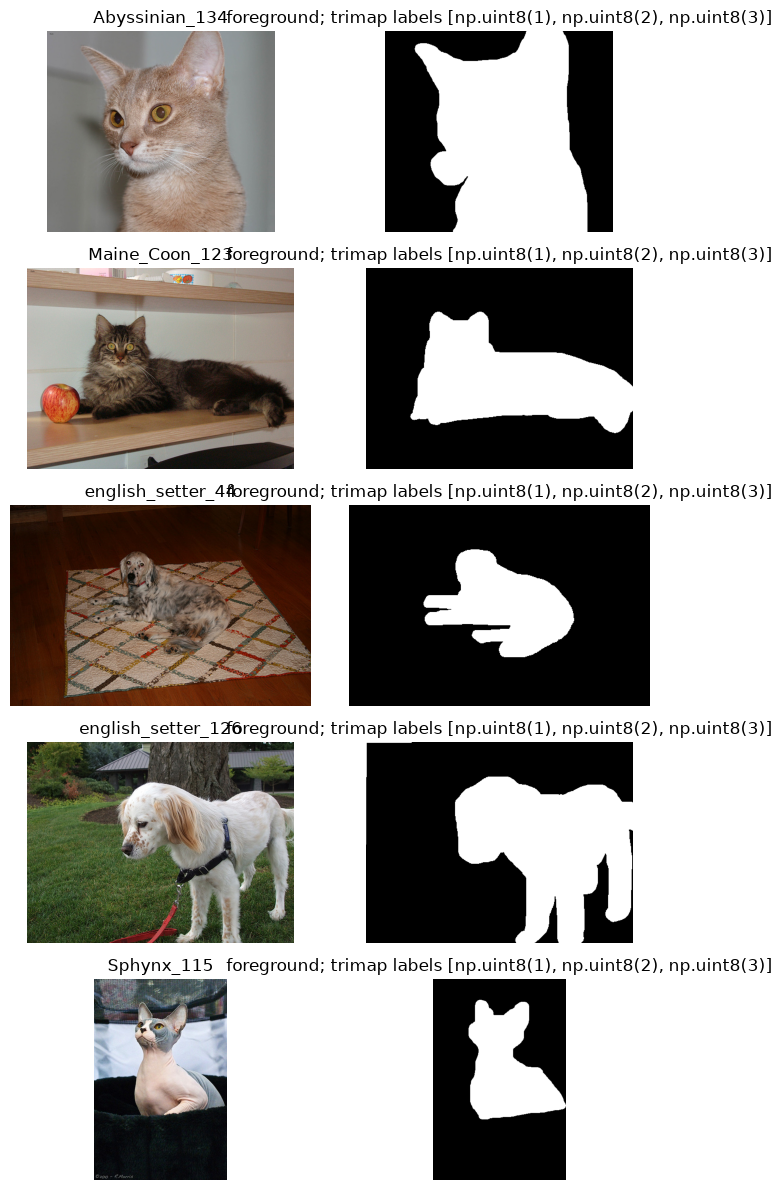

In [2]:
root = Path(os.environ.get('PET_DATA_ROOT','/kaggle/input'))
trimap_dirs = sorted(p for p in root.glob('**/trimaps') if p.is_dir())
if not trimap_dirs:
    raise FileNotFoundError('No trimaps directory. Attach the Oxford-IIIT Pet dataset or set PET_DATA_ROOT.')
mask_dir = trimap_dirs[0]
images = {p.stem:p for p in root.glob('**/*.jpg') if not p.name.startswith('._')}
pairs = [(images[p.stem],p) for p in sorted(mask_dir.glob('*.png'), key=lambda p:p.name)
         if not p.name.startswith('._') and p.stem in images]
assert len(pairs) >= 100, 'Need aligned Oxford pet images and trimaps'
indices = np.random.default_rng(SEED).permutation(len(pairs))
n_train, n_val = int(.8*len(pairs)), int(.1*len(pairs))
train_ids, val_ids, test_ids = indices[:n_train],indices[n_train:n_train+n_val],indices[n_train+n_val:]
assert set(train_ids).isdisjoint(val_ids) and set(train_ids).isdisjoint(test_ids) and set(val_ids).isdisjoint(test_ids)
if SMOKE:
    train_ids, val_ids, test_ids = train_ids[:80],val_ids[:16],test_ids[:16]
splits = {name:[pairs[i] for i in ids] for name,ids in [('train',train_ids),('val',val_ids),('test',test_ids)]}
(OUT/'split.json').write_text(json.dumps({s:[p.stem for p,m in ps] for s,ps in splits.items()},indent=2))
print('image-mask pairs:',len(pairs),'| used:',{s:len(ps) for s,ps in splits.items()})

fig, axes = plt.subplots(5,2,figsize=(7,12))
for row,(image_path,mask_path) in enumerate(splits['train'][:5]):
    image,mask = Image.open(image_path).convert('RGB'),Image.open(mask_path)
    assert image.size == mask.size
    labels = set(np.unique(np.asarray(mask)))
    assert labels <= {1,2,3}
    binary = np.isin(np.asarray(mask),[1,3])
    axes[row,0].imshow(image);axes[row,0].set_title(image_path.stem)
    axes[row,1].imshow(binary,cmap='gray',vmin=0,vmax=1);axes[row,1].set_title(f'foreground; trimap labels {sorted(labels)}')
    for ax in axes[row]:ax.axis('off')
fig.tight_layout();fig.savefig(OUT/'five_pairs.png',dpi=120);plt.show()

In [3]:
class PetPairs(Dataset):
    def __init__(self,pairs,augment=False):
        self.pairs,self.augment = pairs,augment
    def __len__(self):return len(self.pairs)
    def __getitem__(self,i):
        image_path,mask_path = self.pairs[i]
        image = Image.open(image_path).convert('RGB')
        mask = Image.open(mask_path)
        assert image.size == mask.size
        image = TF.resize(image,[SIZE,SIZE],InterpolationMode.BILINEAR)
        mask = TF.resize(mask,[SIZE,SIZE],InterpolationMode.NEAREST)
        if self.augment:
            if random.random()<.5:image,mask = TF.hflip(image),TF.hflip(mask)
            angle=random.uniform(-10,10)
            image=TF.rotate(image,angle,InterpolationMode.BILINEAR,fill=0)
            mask=TF.rotate(mask,angle,InterpolationMode.NEAREST,fill=2)
            image=TF.adjust_brightness(image,random.uniform(.9,1.1))
        target=torch.from_numpy(np.isin(np.asarray(mask),[1,3]).astype('float32')).unsqueeze(0)
        return TF.to_tensor(image),target

generator = torch.Generator().manual_seed(SEED)
train_loader=DataLoader(PetPairs(splits['train'],True),batch_size=BATCH,shuffle=True,
                        num_workers=0,generator=generator)
val_loader=DataLoader(PetPairs(splits['val']),batch_size=BATCH,num_workers=0)
test_loader=DataLoader(PetPairs(splits['test']),batch_size=BATCH,num_workers=0)

In [4]:
def block(cin,cout):
    return nn.Sequential(nn.Conv2d(cin,cout,3,padding=1),nn.ReLU(inplace=True),
                         nn.Conv2d(cout,cout,3,padding=1),nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self,width=32):
        super().__init__()
        w=width
        self.enc1,self.enc2,self.enc3=block(3,w),block(w,2*w),block(2*w,4*w)
        self.pool=nn.MaxPool2d(2)
        self.bottleneck=block(4*w,8*w)
        self.up3,self.up2,self.up1=nn.ConvTranspose2d(8*w,4*w,2,2),nn.ConvTranspose2d(4*w,2*w,2,2),nn.ConvTranspose2d(2*w,w,2,2)
        self.dec3,self.dec2,self.dec1=block(8*w,4*w),block(4*w,2*w),block(2*w,w)
        self.output=nn.Conv2d(w,1,1)
    def forward(self,x,show_shapes=False):
        e1=self.enc1(x);e2=self.enc2(self.pool(e1));e3=self.enc3(self.pool(e2))
        b=self.bottleneck(self.pool(e3))
        d3=self.dec3(torch.cat([self.up3(b),e3],dim=1))
        d2=self.dec2(torch.cat([self.up2(d3),e2],dim=1))
        d1=self.dec1(torch.cat([self.up1(d2),e1],dim=1))
        out=self.output(d1)
        if show_shapes:
            print({name:tuple(t.shape) for name,t in [('enc1',e1),('enc2',e2),('enc3',e3),('bottleneck',b),('dec3',d3),('dec2',d2),('dec1',d1),('output',out)]})
        return out

model=UNet(WIDTH).to(DEVICE)
with torch.no_grad():
    logits=model(torch.zeros(2,3,SIZE,SIZE,device=DEVICE),show_shapes=True)
assert logits.shape==(2,1,SIZE,SIZE)
print('parameters:',sum(p.numel() for p in model.parameters()))

{'enc1': (2, 32, 128, 128), 'enc2': (2, 64, 64, 64), 'enc3': (2, 128, 32, 32), 'bottleneck': (2, 256, 16, 16), 'dec3': (2, 128, 32, 32), 'dec2': (2, 64, 64, 64), 'dec1': (2, 32, 128, 128), 'output': (2, 1, 128, 128)}
parameters: 1925601


Each 3×3 convolution combines neighboring features. A stride-2 pooling layer doubles the distance, in input pixels, between adjacent features at the next level. Subsequent convolutions therefore mix information over a larger part of the original image. With two convolutions per block and three pooling operations, the bottleneck's theoretical receptive field is 68×68 input pixels before decoding. The bottleneck knows more about the pet's overall shape but has lost spatial detail. Skip connections return high-resolution edges and local texture to the decoder, which helps restore boundaries, ears and paws.

{'epoch': 1, 'train_loss': 0.950921833595823, 'loss': 0.8781180236594441, 'dice': 0.7101000688157849, 'iou': 0.5667769534666464}


{'epoch': 2, 'train_loss': 0.7851842012715113, 'loss': 0.7185897777141834, 'dice': 0.7637218020769504, 'iou': 0.6325269244786518}


{'epoch': 3, 'train_loss': 0.6712616272321089, 'loss': 0.675928873848044, 'dice': 0.7843045712690419, 'iou': 0.6667085369606329}


{'epoch': 4, 'train_loss': 0.599743009662112, 'loss': 0.5703815446009656, 'dice': 0.8180948594470194, 'iou': 0.7097299650153756}


{'epoch': 5, 'train_loss': 0.557561294877642, 'loss': 0.6055047430592073, 'dice': 0.7997840784584721, 'iou': 0.6853488582884673}


{'epoch': 6, 'train_loss': 0.5119034793928608, 'loss': 0.5412642300854839, 'dice': 0.8254259991110214, 'iou': 0.721555913091992}


{'epoch': 7, 'train_loss': 0.47630335533731843, 'loss': 0.4633384868401797, 'dice': 0.8550336736185926, 'iou': 0.7624407483820158}


{'epoch': 8, 'train_loss': 0.4528243052136753, 'loss': 0.4622437832965257, 'dice': 0.8560891525271173, 'iou': 0.7623319022149005}


{'epoch': 9, 'train_loss': 0.4327976030571051, 'loss': 0.45645355307200924, 'dice': 0.8551942156946457, 'iou': 0.7617630424468048}


{'epoch': 10, 'train_loss': 0.41576486616237884, 'loss': 0.4454896799282389, 'dice': 0.8558379876680989, 'iou': 0.763949195994538}
training seconds: 465.3


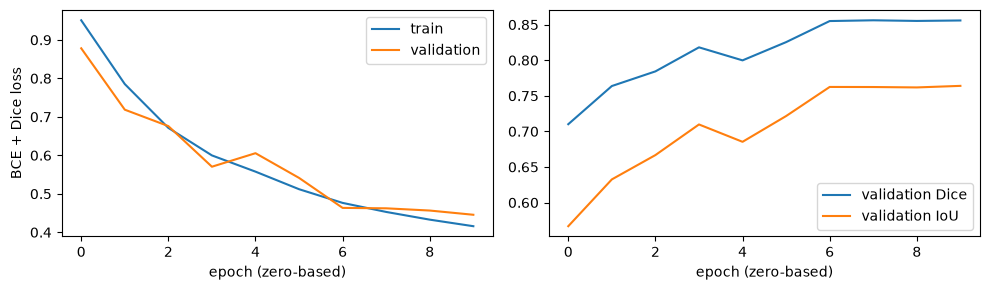

In [5]:
bce=nn.BCEWithLogitsLoss()
def loss_fn(logits,target):
    probability=logits.sigmoid()
    dims=(1,2,3)
    soft_dice=(2*(probability*target).sum(dims)+1e-6)/(probability.sum(dims)+target.sum(dims)+1e-6)
    return bce(logits,target)+(1-soft_dice).mean()

@torch.no_grad()
def evaluate(loader):
    model.eval()
    losses,dices,ious=[],[],[]
    for image,target in loader:
        image,target=image.to(DEVICE),target.to(DEVICE)
        logits=model(image)
        losses.extend([loss_fn(logits,target).item()]*len(image))
        pred=logits.sigmoid()>=.5
        gt=target.bool()
        intersection=(pred&gt).sum((1,2,3)).float()
        p,g=pred.sum((1,2,3)).float(),gt.sum((1,2,3)).float()
        dices.extend(((2*intersection+1e-6)/(p+g+1e-6)).cpu().tolist())
        ious.extend(((intersection+1e-6)/(p+g-intersection+1e-6)).cpu().tolist())
    return {'loss':float(np.mean(losses)),'dice':float(np.mean(dices)),'iou':float(np.mean(ious))}

optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
history=[];best=-1;start=time.perf_counter()
for epoch in range(EPOCHS):
    model.train();total,n=0.,0
    for image,target in train_loader:
        image,target=image.to(DEVICE),target.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss=loss_fn(model(image),target)
        loss.backward();optimizer.step()
        total+=loss.item()*len(image);n+=len(image)
    metrics=evaluate(val_loader)
    history.append({'epoch':epoch+1,'train_loss':total/n,**metrics})
    if metrics['dice']>best:
        best=metrics['dice']
        torch.save({'state_dict':model.state_dict(),'width':WIDTH,'size':SIZE,
                    'seed':SEED,'epoch':epoch+1,'val_dice':best,'smoke':SMOKE},OUT/'best_unet.pt')
    print(history[-1])
print('training seconds:',round(time.perf_counter()-start,1))
(OUT/'history.json').write_text(json.dumps(history,indent=2))
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].plot([h['train_loss'] for h in history],label='train')
axes[0].plot([h['loss'] for h in history],label='validation');axes[0].set_ylabel('BCE + Dice loss')
axes[1].plot([h['dice'] for h in history],label='validation Dice')
axes[1].plot([h['iou'] for h in history],label='validation IoU')
for ax in axes:ax.set_xlabel('epoch (zero-based)');ax.legend()
fig.tight_layout();fig.savefig(OUT/'learning_curves.png',dpi=140);plt.show()

selected epoch: 8 | held-out test: {'loss': 0.454376046446244, 'dice': 0.857591887612009, 'iou': 0.7651823355408209}


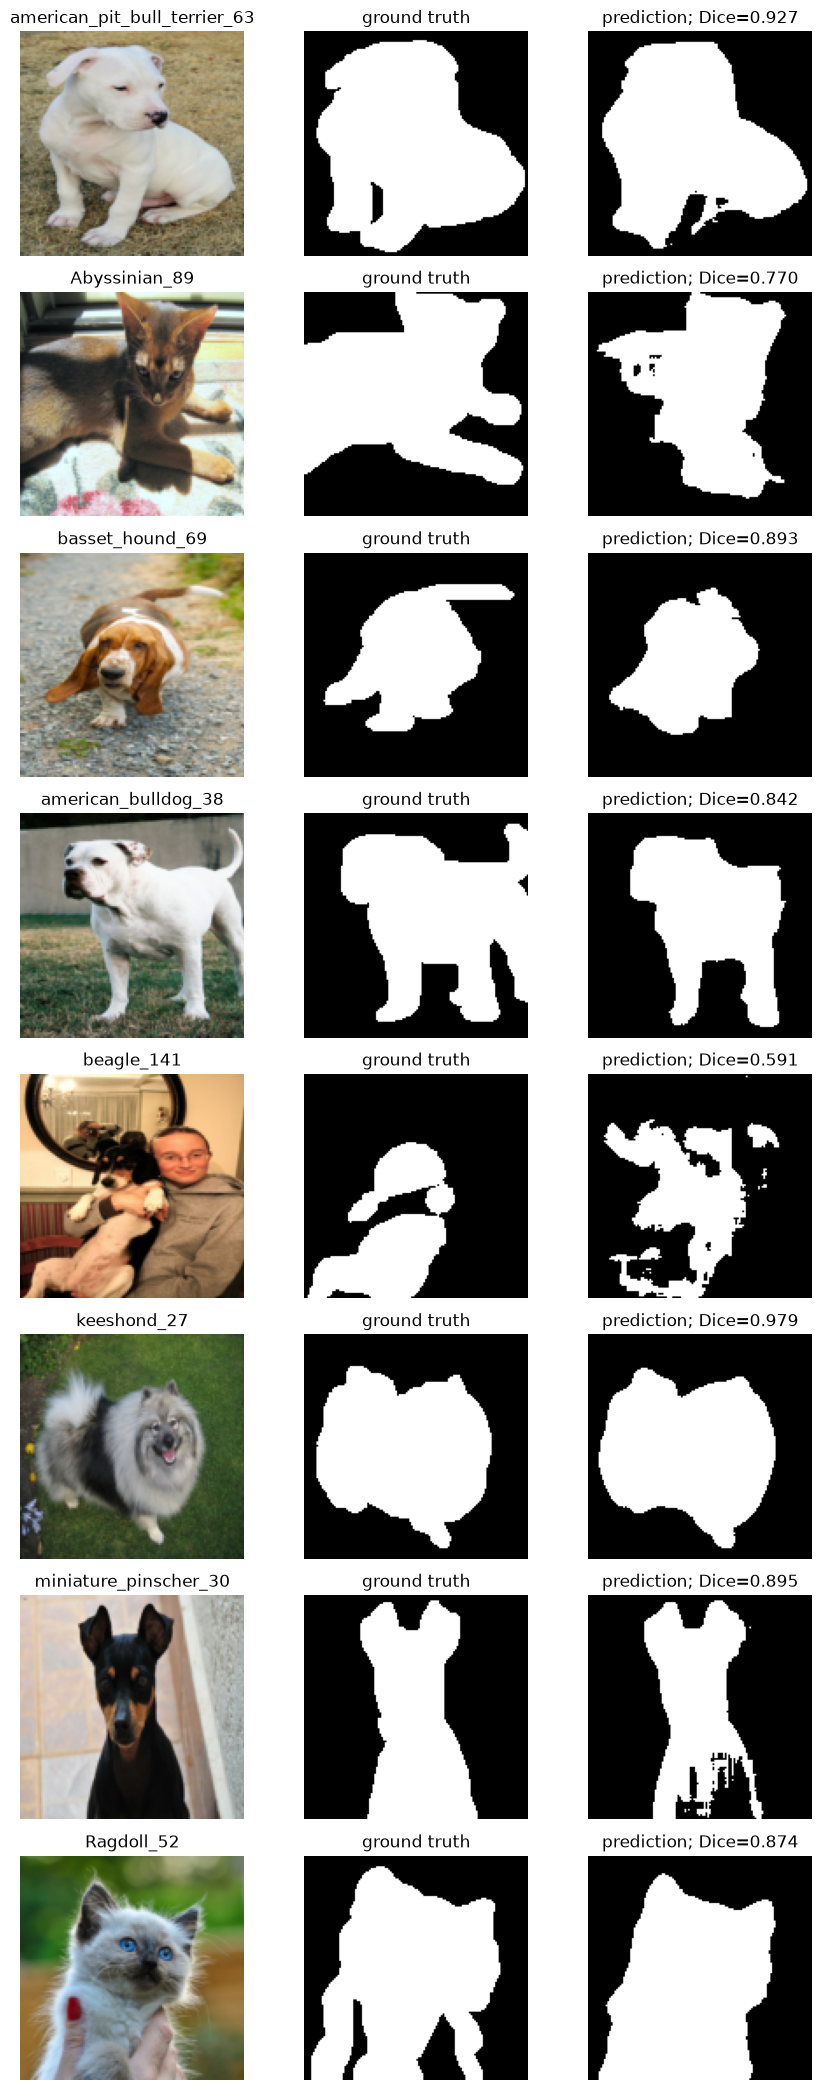

Two weakest of the eight examples: [(4, 0.5907142162322998), (1, 0.7704806327819824)]


In [6]:
checkpoint=torch.load(OUT/'best_unet.pt',map_location=DEVICE,weights_only=True)
model.load_state_dict(checkpoint['state_dict'])
# This is the first test-set evaluation, after the validation choice is fixed.
test_metrics=evaluate(test_loader)
(OUT/'test_metrics.json').write_text(json.dumps({'mode':'smoke' if SMOKE else 'full',
    'selected_epoch':checkpoint['epoch'],'test_images':len(test_ids),**test_metrics},indent=2))
print('selected epoch:',checkpoint['epoch'],'| held-out test:',test_metrics)

test_dataset=test_loader.dataset
fig,axes=plt.subplots(8,3,figsize=(9,21))
visual_scores=[]
model.eval()
with torch.no_grad():
    for row in range(8):
        image,target=test_dataset[row]
        pred=(model(image[None].to(DEVICE)).sigmoid()[0,0].cpu()>=.5)
        gt=target[0].bool()
        dice=((2*(pred&gt).sum()+1e-6)/(pred.sum()+gt.sum()+1e-6)).item()
        visual_scores.append(dice)
        axes[row,0].imshow(image.permute(1,2,0));axes[row,0].set_title(splits['test'][row][0].stem)
        axes[row,1].imshow(gt,cmap='gray',vmin=0,vmax=1);axes[row,1].set_title('ground truth')
        axes[row,2].imshow(pred,cmap='gray',vmin=0,vmax=1);axes[row,2].set_title(f'prediction; Dice={dice:.3f}')
        for ax in axes[row]:ax.axis('off')
fig.tight_layout();fig.savefig(OUT/'eight_test_predictions.png',dpi=120);plt.show()
print('Two weakest of the eight examples:',sorted(enumerate(visual_scores),key=lambda x:x[1])[:2])

The full run used 5,912 training, 739 validation and 739 test images, width 32, and ten epochs. Epoch 8 was selected by validation Dice (0.8561). The held-out test set scored mean Dice **0.8576** and IoU **0.7652**, with BCE + Dice loss 0.4544. Training loss decreased from 0.9509 to 0.4158. Epoch 10 had lower validation loss but slightly lower validation Dice; selection followed the stated Dice criterion.

Two visible failure cases are `beagle_141` (Dice 0.591) and `Abyssinian_89` (0.770). The beagle is held by a person in a cluttered indoor scene: the prediction is fragmented, misses parts of the dog, and includes unrelated foreground. For the Abyssinian, the head and near legs are recovered, but much of the cat's body on the left is missed. Partial views, occlusion and similar local colors make the boundary harder to recover. In contrast, `keeshond_27` has a nearly complete silhouette (Dice 0.979). Thin tails, ears and boundary details still need attention even in otherwise good examples.

The held-out test set was not used to choose a checkpoint or change hyperparameters. Mean per-image Dice and IoU are reported because background-dominated pixel accuracy can hide failures on small pets. Label 3 (uncertain boundary) was counted as foreground, and nearest-neighbor resizing preserved mask labels. The saved split file identifies every image. Sorting explicitly by filename keeps the split order consistent across operating systems. The earlier subset run used a different platform ordering and model width, so its scores are not a controlled estimate of the effect of more training data alone.

Oxford-IIIT Pet: Parkhi et al., *Cats and Dogs*, CVPR 2012. Dataset images and derived figures retain [CC BY-SA 4.0 attribution requirements](https://www.robots.ox.ac.uk/~vgg/data/pets/).